# W04. Psychometria obliczeniowa

**Wersja źródła:** 1.1.4 · **Data:** 2026-11-03

Przykład sześciu pozycji Likerta (1–5); dane syntetyczne; osobna ilustracja binarnego modelu IRT 2PL.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("NumPy", np.__version__, "pandas", pd.__version__)


NumPy 2.5.4 pandas 3.1.1


## Generowanie danych
P5 sformułowana odwrotnie. P6 ma celowo małe obciążenie wspólnym czynnikiem; około 3% wartości jest nieobserwowanych.

In [2]:
rng = np.random.default_rng(42)
n = 240
pozycje = [f"P{i}" for i in range(1, 7)]
theta_latent = rng.normal(0, 1, size=(n, 1))
ladunki = np.array([.9, .8, .75, .9, .8, .05])
tab = np.clip(np.rint(
    3 + theta_latent * ladunki + rng.normal(0, .8, (n, 6))
), 1, 5).astype(float)
tab[:, 4] = 6 - tab[:, 4]
tab[rng.random((n, 6)) < .03] = np.nan
dane = pd.DataFrame(tab, columns=pozycje)
assert len(dane) == 240
print("Braki", dane.isna().sum().to_dict())


Braki {'P1': 8, 'P2': 11, 'P3': 4, 'P4': 6, 'P5': 3, 'P6': 4}


## Przekształcenie i statystyki
Analiza przypadków jest uproszczeniem na potrzeby ćwiczenia

In [3]:
analiza = dane.dropna(subset=pozycje).copy()
analiza["P5"] = 6 - analiza["P5"]
analiza["wynik"] = analiza[pozycje].sum(axis=1)
assert analiza["wynik"].between(6, 30).all()
print(analiza["wynik"].describe().round(2))


count    205.00
mean      17.51
std        3.99
min        7.00
25%       15.00
50%       17.00
75%       21.00
max       28.00
Name: wynik, dtype: float64


## Współczynnik alfa i skorygowana korelacja
Alfa wymaga oceny założeń. Korelację item–rest liczymy z sumą pozostałych pozycji.

In [4]:
def alfa_cronbacha(df):
    k = df.shape[1]
    suma = df.sum(axis=1)
    return (k / (k - 1) *
            (1 - df.var(ddof=1).sum() / suma.var(ddof=1)))

alpha6 = alfa_cronbacha(analiza[pozycje])
alpha5 = alfa_cronbacha(analiza[pozycje[:-1]])
item_rest = pd.Series({
    x: analiza[x].corr(analiza[pozycje].drop(columns=x).sum(axis=1))
    for x in pozycje
})
print("N:", len(analiza), "alfa6:", round(alpha6, 3),
      "alfa5:", round(alpha5, 3))
print(item_rest.round(3))
assert item_rest["P6"] < item_rest["P1"]


N: 205 alfa6: 0.711 alfa5: 0.76
P1    0.525
P2    0.521
P3    0.480
P4    0.551
P5    0.496
P6    0.067
dtype: float64


## Rozkład i własności pozycji
Wykresy dotyczą wczytanych powyżej danych

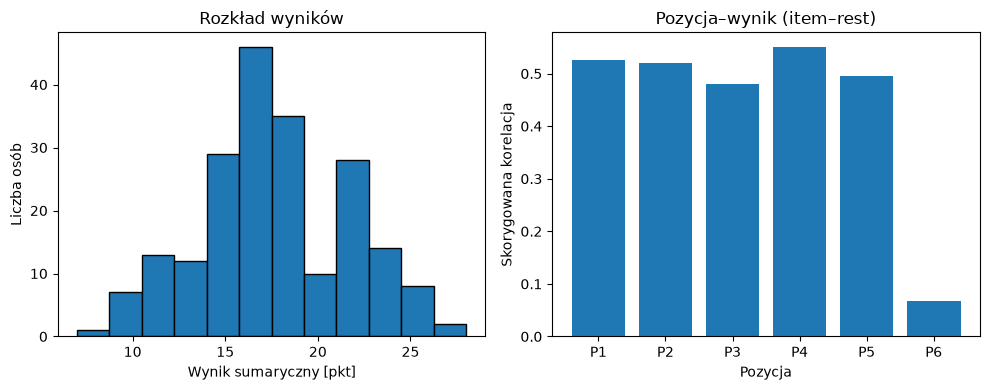

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(analiza.wynik, bins=12, edgecolor="black")
ax[0].set(xlabel="Wynik sumaryczny [pkt]", ylabel="Liczba osób",
          title="Rozkład wyników")
ax[1].bar(item_rest.index, item_rest.values)
ax[1].set(xlabel="Pozycja", ylabel="Skorygowana korelacja",
          title="Pozycja–wynik (item–rest)")
fig.tight_layout()
plt.show()


## IRT: model 2PL dla pozycji dychotomicznych
**Oddzielna ilustracja**: poniższe równania nie są dopasowaniem modelu do ordinalnych odpowiedzi P1–P6.

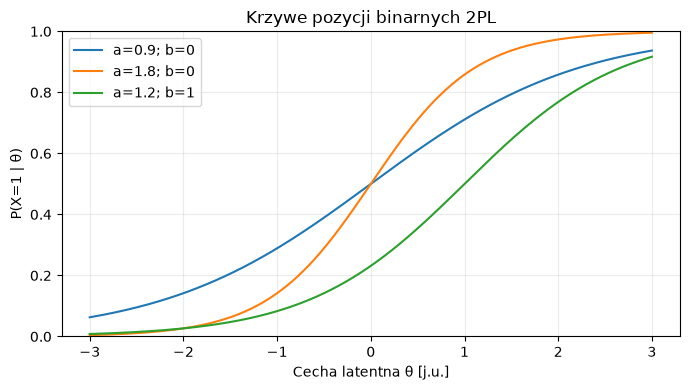

In [6]:
theta = np.linspace(-3, 3, 301)
params = [(.9, 0), (1.8, 0), (1.2, 1)]
fig, ax = plt.subplots(figsize=(7, 4))
for a, b in params:
    prob = 1 / (1 + np.exp(-a * (theta - b)))
    ax.plot(theta, prob, label=f"a={a}; b={b}")
ax.set(xlabel="Cecha latentna θ [j.u.]",
       ylabel="P(X=1 | θ)",
       ylim=(0, 1), title="Krzywe pozycji binarnych 2PL")
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
plt.show()


## Interpretacja
Wysoka alfa nie dowodzi jednowymiarowości ani trafności. Omega wymaga adekwatnego modelu czynnikowego; tutaj nie jest estymowana.